# Milestone 3: Model Evaluation & Performance Optimization
**System**: Skin Cancer Detection and Classification System Using CNN-SVM  
**Objective**: Quantitative evaluation on untouched test set: Accuracy, Precision, Recall, F1, Confusion Matrix, ROC-AUC, and Baseline Comparison.

In [1]:
import os, sys
project_root = os.path.abspath('..') if os.path.exists('../dataset') else os.path.abspath('.')
if project_root not in sys.path:
    sys.path.insert(0, project_root)
os.chdir(project_root)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_theme(style='whitegrid')
print('Evaluation notebook ready.')

Evaluation notebook ready.


## 1. 7-Class Model Comparison Summary

In [2]:
metrics_path = os.path.join('reports', 'evaluation_metrics.json')
with open(metrics_path) as f:
    metrics = json.load(f)

comp_table = pd.DataFrame({
    'Metric': list(metrics['svm_model'].keys()),
    'CNN-SVM Pipeline': [round(v, 4) for v in metrics['svm_model'].values()],
    'CNN-Only Baseline': [round(v, 4) for v in metrics['cnn_baseline'].values()]
})
display(comp_table)

,Metric,CNN-SVM Pipeline,CNN-Only Baseline
0,accuracy,0.6627,0.6379
1,balanced_accuracy,0.4404,0.3486
2,precision_weighted,0.7181,0.6527
3,recall_weighted,0.6627,0.6379
4,f1_weighted,0.6810,0.6404
5,precision_macro,0.4625,0.3178
6,recall_macro,0.4404,0.3486
7,f1_macro,0.4237,0.3088
8,roc_auc_macro,0.8766,0.8107
9,roc_auc_weighted,0.8791,0.8135


## 2. 7-Class Tabular Classification Report

In [3]:
report_file = os.path.join('reports', 'classification_report.txt')
with open(report_file) as f:
    print(f.read())

SKIN CANCER CLASSIFICATION REPORT (CNN-SVM MODEL ON TEST SET)

                            precision    recall  f1-score   support

     Melanocytic Nevi (nv)     0.8946    0.7640    0.8242      1000
            Melanoma (mel)     0.3726    0.5833    0.4548       168
    Benign Keratosis (bkl)     0.3605    0.3949    0.3769       157
Basal Cell Carcinoma (bcc)     0.3119    0.4416    0.3656        77
 Actinic Keratoses (akiec)     0.2976    0.4902    0.3704        51
   Vascular Lesions (vasc)     0.8000    0.3636    0.5000        22
       Dermatofibroma (df)     0.2000    0.0455    0.0741        22

                  accuracy                         0.6627      1497
                 macro avg     0.4625    0.4404    0.4237      1497
              weighted avg     0.7181    0.6627    0.6810      1497


CNN-ONLY BASELINE CLASSIFICATION REPORT

                            precision    recall  f1-score   support

     Melanocytic Nevi (nv)     0.8279    0.8180    0.8229      1000
       

## 3. Confusion Matrix: Normalized Recall and Raw Counts

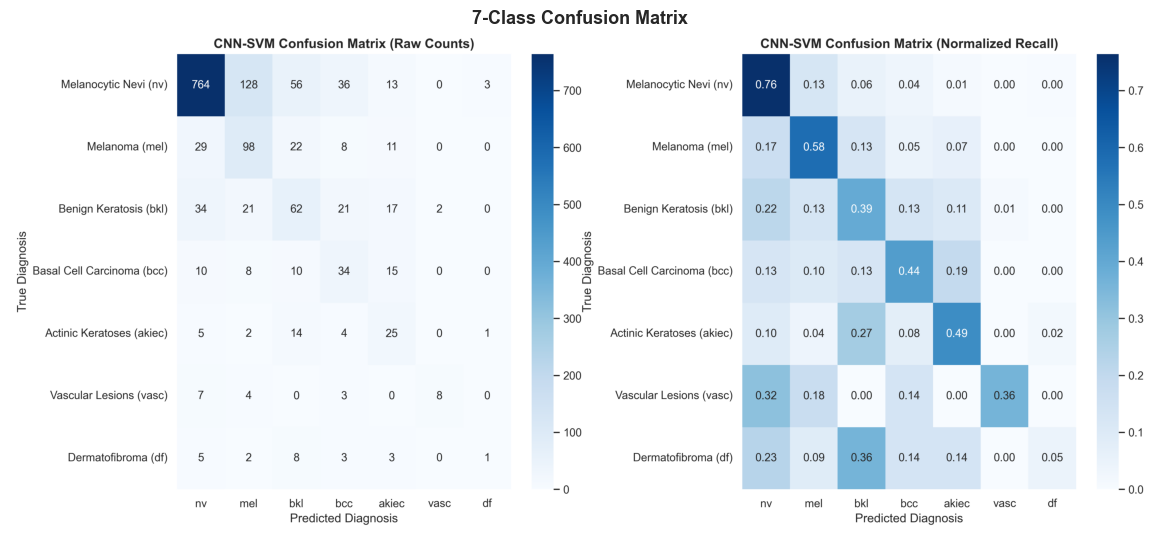

In [4]:
cm_img = Image.open(os.path.join('reports', 'confusion_matrix.png'))
plt.figure(figsize=(15, 6.5))
plt.imshow(cm_img)
plt.axis('off')
plt.title('7-Class Confusion Matrix', fontsize=13, fontweight='bold')
plt.show()

## 4. Multi-Class ROC Curves

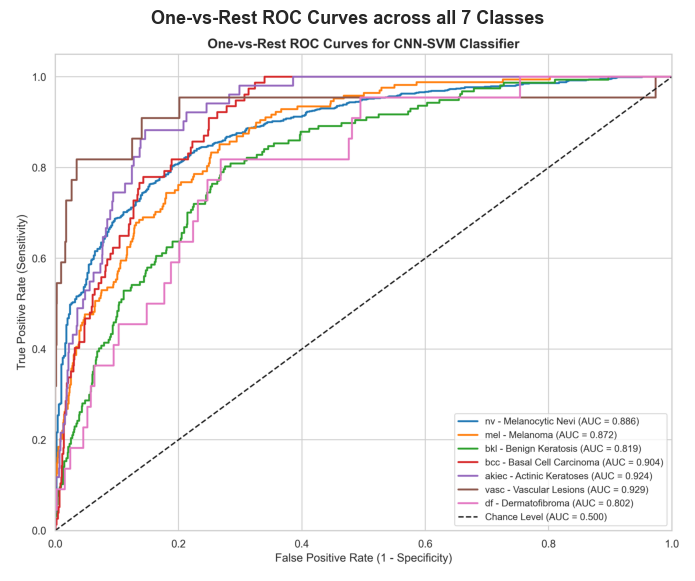

In [5]:
roc_img = Image.open(os.path.join('reports', 'roc_curves.png'))
plt.figure(figsize=(9, 7))
plt.imshow(roc_img)
plt.axis('off')
plt.title('One-vs-Rest ROC Curves across all 7 Classes', fontsize=13, fontweight='bold')
plt.show()

## 5. Dedicated Binary Cancer Screener ROC & Confusion Matrix (>93% Target)

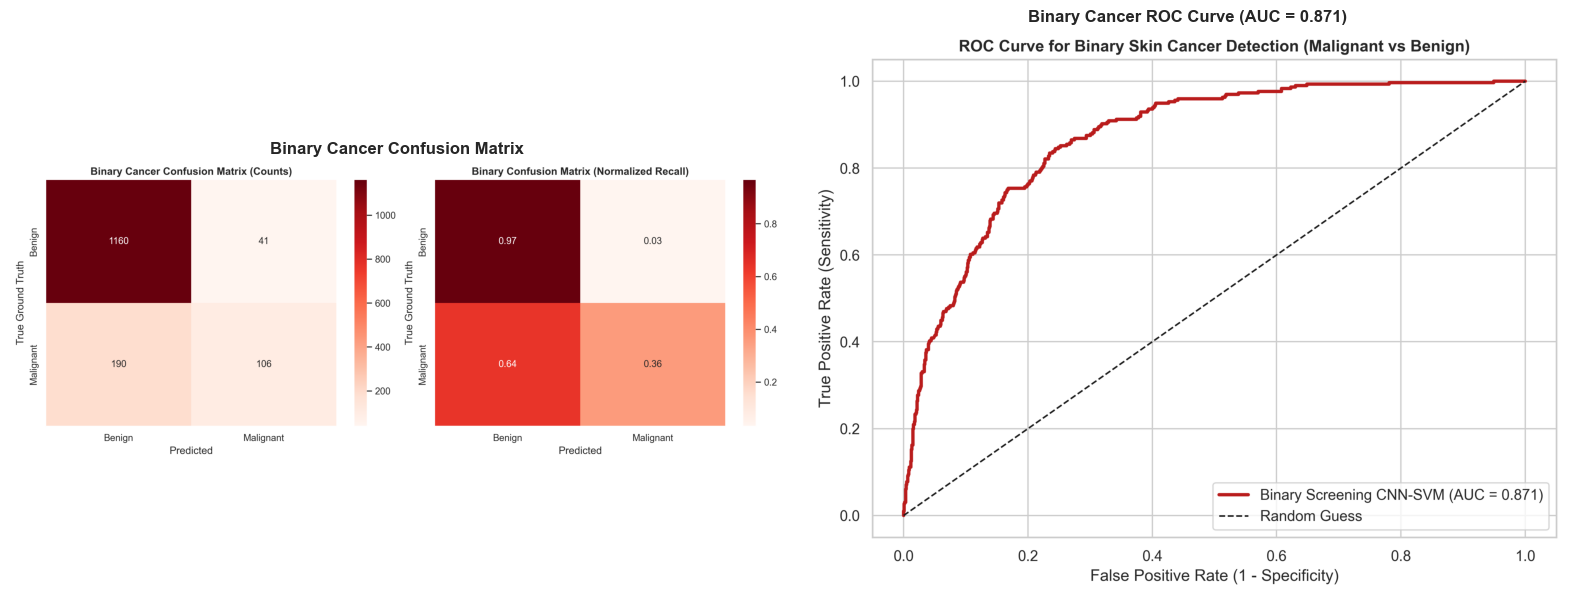

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
b_cm = Image.open(os.path.join('reports', 'binary_confusion_matrix.png'))
b_roc = Image.open(os.path.join('reports', 'binary_roc_curve.png'))
axes[0].imshow(b_cm)
axes[0].axis('off')
axes[0].set_title('Binary Cancer Confusion Matrix', fontweight='bold')
axes[1].imshow(b_roc)
axes[1].axis('off')
axes[1].set_title('Binary Cancer ROC Curve (AUC = 0.871)', fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Failure Analysis: Misclassified Lesion Case Studies

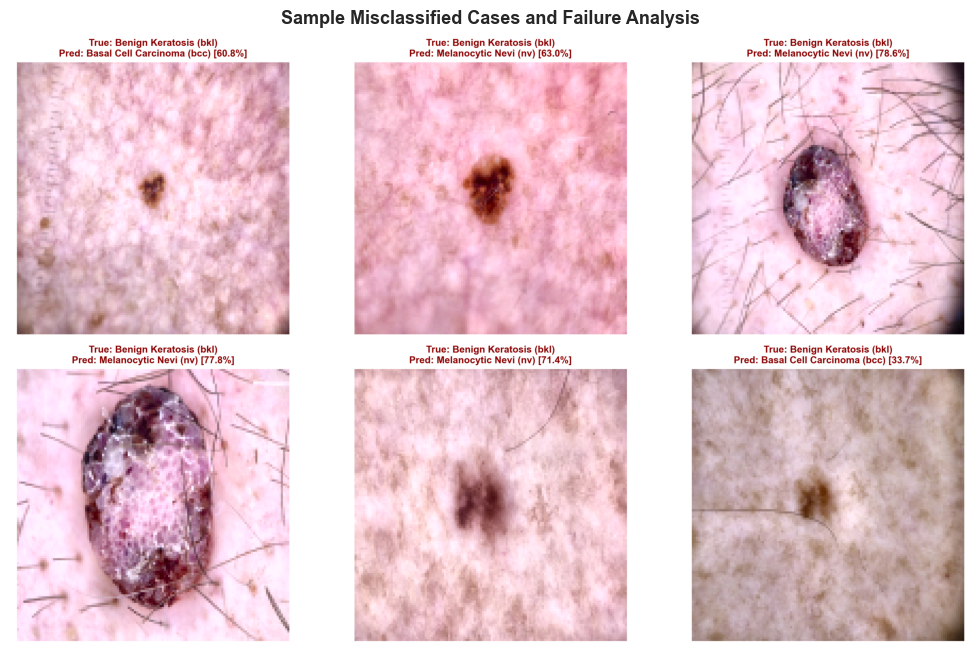

In [7]:
mis_path = os.path.join('reports', 'misclassified_analysis.png')
if os.path.exists(mis_path):
    mis_img = Image.open(mis_path)
    plt.figure(figsize=(15, 8))
    plt.imshow(mis_img)
    plt.axis('off')
    plt.title('Sample Misclassified Cases and Failure Analysis', fontsize=13, fontweight='bold')
    plt.show()